## PIMCS: Example Notebook

_The notebook below is run on an 8-core M2 Macbook Air (2022) so the timings are representative of what one can expect on fairly **standard laptop hardware**._

First we use the following imports,

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import e, hbar

from pimcs import Dicke, destroy, excited, ground, jspin, mcsolve, rotated_qubits

EV_TO_FS = 1e15 * hbar / e

#### Example 1: Tavis-Cummings model

- set up the system using operators and `Dicke` class in similar way to QuTiP piqs
- construct the initial state (also supporting `rotated qubits` for symmetry broken state)
- solve the system (stochastically) using `mcsolve` function


This problem is from <a href="https://doi.org/10.1515/nanoph-2025-0427">Freter et al., 2025</a> and is used to benchmark this library against their PIBS method (a density-matrix algorithm). With further optimizations shown in the second example, we can obtain the same results in a few seconds on a laptop rather than hours on a server.

_Note:_ `rotated_qubits(θ)` constructs the wave function, $\bigotimes_j ~ \exp(-i \hat{\sigma}_x \theta / 2) \left|\uparrow_j\right\rangle$

All of `ground`, `excited`, `rotated_qubits` and `coherent_state` produce photon vacuum states.

Simulation 200/200 complete (0.092 s per trajectory)


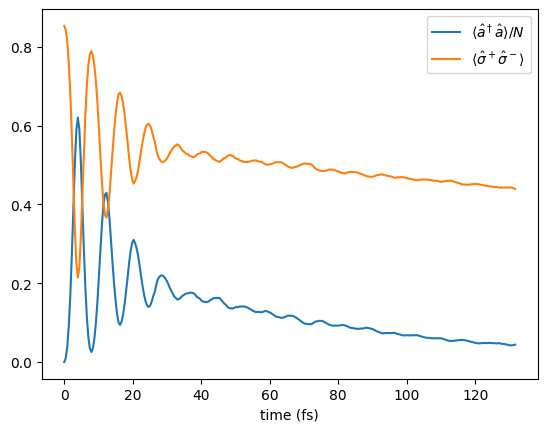

In [2]:
#system parameters
N = 60
CavityTruncation = N

OmegaC = 0
OmegaA = 0.35
Coupling = 0.4 / np.sqrt(N)

# setup system in a similar way to qutip.piqs
Jz, Jp, Jm = jspin("z+-") # note: there is no size parameter for operators
a = destroy()

# Tavis-Cummings model
H = OmegaC * a.dag()*a + OmegaA * Jz + Coupling * (Jm * a.dag() + Jp * a)

# construct the system, also supports photon lindblad channels; photon_loss (a), cavity_emission for (a†σ-) and cavity_absorption for (aσ+)
system = Dicke(
    (N, CavityTruncation),
    H,
    photon_loss_rate = 0.01,
    local_dephasing_rate = 4 * 0.0075,
    local_emission_rate = 0.001,
)

psi0 = rotated_qubits(np.pi / 4) # initial wave function (all spins up)
times = np.linspace(0, 200, 300) # times at which to output expectation values

data = mcsolve(
    system, psi0, times,
    [a.dag()*a, Jz],              # operators to measure during simulation
    number_of_trajectories = 200, # total number of Monte Carlo simulations to run 
    number_of_cpus         = 8,   # number of simulations to run in parallel (ideally = number of CPU cores)
)

# results of mcsolve is a list of np.array of expectation values in same order as declared in mcsolve()
expected_photon_occupation = data[0]
expected_spin_up_count = N/2 + data[1]

plt.plot(times * EV_TO_FS, expected_photon_occupation / N, label = "$\\langle \\hat{a}^\\dagger \\hat{a} \\rangle / N$")
plt.plot(times * EV_TO_FS, expected_spin_up_count / N, label = "$\\langle \\hat{\\sigma}^+ \\hat{\\sigma}^- \\rangle$")

plt.xlabel("time (fs)")
plt.legend(loc = "upper right");

**Diagonal State Optimisation**

For a model like Tavis-Cummings, there is a $U(1)$ symmetry &mdash; the Hamiltonian preserves (commutes with) with $\hat{U} = \hat{a}^\dagger \hat{a} + \hat{J}_z$ One can exploit this symmetry when starting in an eigenstate of $\hat{U}$, to reduce the runtime complexity from $\mathcal{O}(N^3)$ to $\mathcal{O}(N^2)$ by eliminating the photon space.

The library will print this message when this optimisation is (automatically!) detected.

Info: using diagonal state optimisation, photon truncation of 140 ignored.
 > this mode can handle an unbounded photon Hilbert space
Simulation 200/200 complete (0.009 s per trajectory)


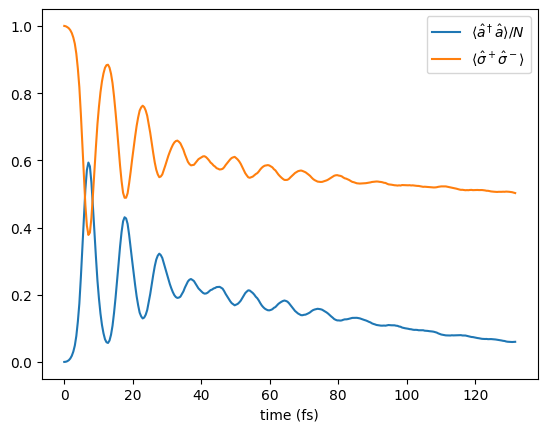

In [3]:
#system parameters
N = 140
CavityTruncation = N

OmegaC = 0
OmegaA = 0.35
Coupling = 0.4 / np.sqrt(N)

H = OmegaC * a.dag()*a + OmegaA * Jz + Coupling * (Jm * a.dag() + Jp * a)

system = Dicke(
    (N, CavityTruncation),
    H,
    photon_loss_rate = 0.01,
    local_dephasing_rate = 4 * 0.0075,
    local_emission_rate = 0.001,
)

psi0 = excited() # initial wave function (all spins up)

data = mcsolve(
    system, psi0, times,
    [a.dag()*a, Jz],
    number_of_trajectories = 200,
    number_of_cpus = 8,
)

expected_photon_occupation = data[0]
expected_spin_up_count = N/2 + data[1]

plt.plot(times * EV_TO_FS, expected_photon_occupation / N, label = "$\\langle \\hat{a}^\\dagger \\hat{a} \\rangle / N$")
plt.plot(times * EV_TO_FS, expected_spin_up_count / N, label = "$\\langle \\hat{\\sigma}^+ \\hat{\\sigma}^- \\rangle$")

plt.xlabel("time (fs)")
plt.legend(loc = "upper right");

**Time-dependent Hamiltonian**

This library also fully supports time-dependent Hamiltonians with a simple interface:
- define a function with single argument: $f(t)$
- then mulitply an operator expression by this function

Simulation 200/200 complete (0.243 s per trajectory)


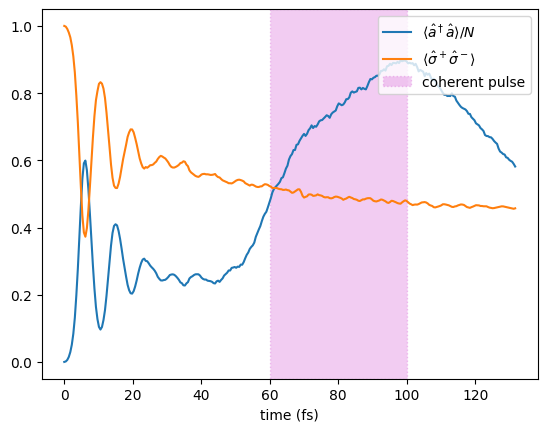

In [4]:
N = 50 # smaller system as we no longer have the U(1) symmetry with this pump
CavityTruncation = 2*N # increase for this example

OmegaC = 0
OmegaA = 0.35
Coupling = 0.4 / np.sqrt(N)

H = OmegaC * a.dag()*a + OmegaA * Jz + Coupling * (Jm * a.dag() + Jp * a)

# create Gaussian pump centred at t = 80 fs with a standard deviation of 20 fs

F_pump = 50
sigma = 20 / EV_TO_FS
t_0 = 80 / EV_TO_FS

def gaussian_pulse(t):
    return F_pump / np.sqrt(2 * np.pi * sigma**2) * np.exp(-(t - t_0)**2 / (2 * sigma**2))

# add coherent pump
H += gaussian_pulse * (Jp + Jm)

system = Dicke(
    (N, CavityTruncation),
    H,
    photon_loss_rate = 0.01,
    local_dephasing_rate = 4 * 0.0075,
    local_emission_rate = 0.001,
)

data = mcsolve(
    system, psi0, times,
    [a.dag()*a, Jz],
    number_of_trajectories = 200,
    number_of_cpus = 8,
)

expected_photon_occupation = data[0]
expected_spin_up_count = N/2 + data[1]

plt.plot(times * EV_TO_FS, expected_photon_occupation / N, label = "$\\langle \\hat{a}^\\dagger \\hat{a} \\rangle / N$")
plt.plot(times * EV_TO_FS, expected_spin_up_count / N, label = "$\\langle \\hat{\\sigma}^+ \\hat{\\sigma}^- \\rangle$")
plt.axvspan((t_0 - sigma) * EV_TO_FS, (t_0 + sigma) * EV_TO_FS, color = 'm', alpha = 0.2, ls = ':', label = "coherent pulse")

plt.xlabel("time (fs)")
plt.legend(loc = "upper right");

#### Example 2: Dicke Model

In this section we will showcase another optimization which is to use a displacement transform ($D(\alpha) = \exp(\alpha \hat{a}^\dagger - \alpha^* \hat{a}$) to compress the photon occupations into a very small number of modes (typically independent of $N$). The requirement for the effectiveness of this transform is that $|\langle\hat{a}\rangle|^2 \approx \langle \hat{a}^\dagger \hat{a} \rangle$.

One such model with this property is the Dicke model, where we use <a href="https://doi.org/10.1103/PhysRevLett.118.123602">Kirton and Keeling, 2017</a> as a case study.

First we run a single trajectory to see if the requirement indeed holds.

Simulation 1/1 complete (0.446 s per trajectory)


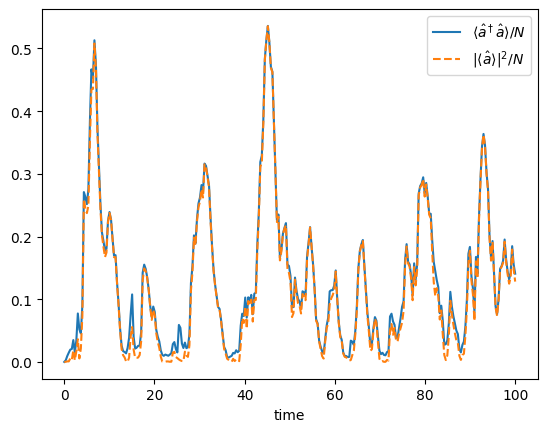

In [5]:
#system parameters
N = 20
CavityTruncation = N

OmegaC = 1
OmegaA = 2 * 0.5
Coupling = 2 * 0.9 / np.sqrt(N)

Jz, Jx = jspin("zx")
a = destroy()

# Dicke model
H = OmegaC * a.dag()*a + OmegaA * Jz + Coupling * Jx * (a.dag() + a)

system = Dicke(
    (N, CavityTruncation),
    H,
    photon_loss_rate = 1,
    local_dephasing_rate = 4 * 0.1,
    local_emission_rate = 0.2,
)

psi0 = ground()
times = np.linspace(0, 100, 300)

data = mcsolve(
    system, psi0, times,
    [a.dag() * a, a], 
    number_of_trajectories = 1, 
    number_of_cpus = 1,
    enable_displacement = True, # enable displacement unitary transform!!
)

expected_photon_occupation = data[0]
expected_annihilation = data[1]

plt.plot(times, expected_photon_occupation / N, label = "$\\langle \\hat{a}^\\dagger \\hat{a} \\rangle / N$")
plt.plot(times, np.abs(expected_annihilation)**2 / N, ls = "--", label = "$|\\langle \\hat{a} \\rangle|^2 / N$")
plt.xlabel("time")
plt.legend(loc = "upper right");

**Displacement Transform Optimization**

With this verified, we can now aggressively truncated the cavity mode to a small number (~4 works well for this system), and this is independent of $N$

Simulation 200/200 complete (0.358 s per trajectory)


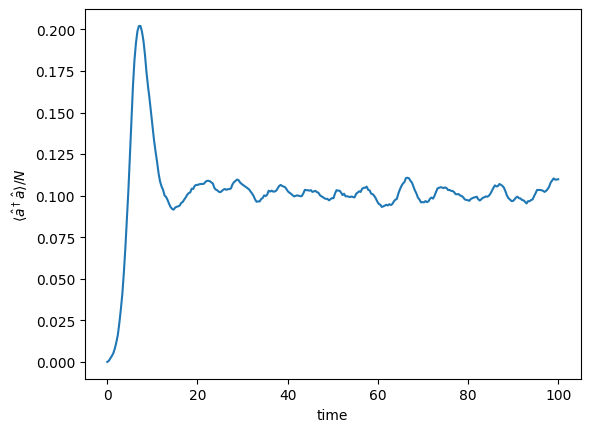

In [6]:
#system parameters
N = 100
CavityTruncation = 4

OmegaC = 1
OmegaA = 2 * 0.5
Coupling = 2 * 0.9 / np.sqrt(N)

H = OmegaC * a.dag()*a + OmegaA * Jz + Coupling * Jx * (a.dag() + a)

system = Dicke(
    (N, CavityTruncation),
    H,
    photon_loss_rate = 1,
    local_dephasing_rate = 4 * 0.1,
    local_emission_rate = 0.2,
)

data = mcsolve(
    system, psi0, times,
    [a.dag() * a], 
    number_of_trajectories = 200, 
    number_of_cpus = 8,
    enable_displacement = True, # enable displacement unitary transform!!
)

expected_photon_occupation = data[0]
plt.plot(times, expected_photon_occupation / N)
plt.xlabel("time")
plt.ylabel("$\\langle \\hat{a}^\\dagger \\hat{a} \\rangle / N$");

From the results we see that this confirms the steady state photon occupation per emitted is ~0.1 as predicted by the cumulant expansion. In a few minutes, this already goes beyond density matrix calculations which took many hours on a powerful server for $N = 60$ results, and on similar hardware and time, it is possible to go much higher with the runtime reduced to $\mathcal{O}(N^2)$ compared to density matrix methods which are $\mathcal{O}(N^5)$.